In [198]:
import numpy as np
import pandas as pd
import scipy as sp
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns


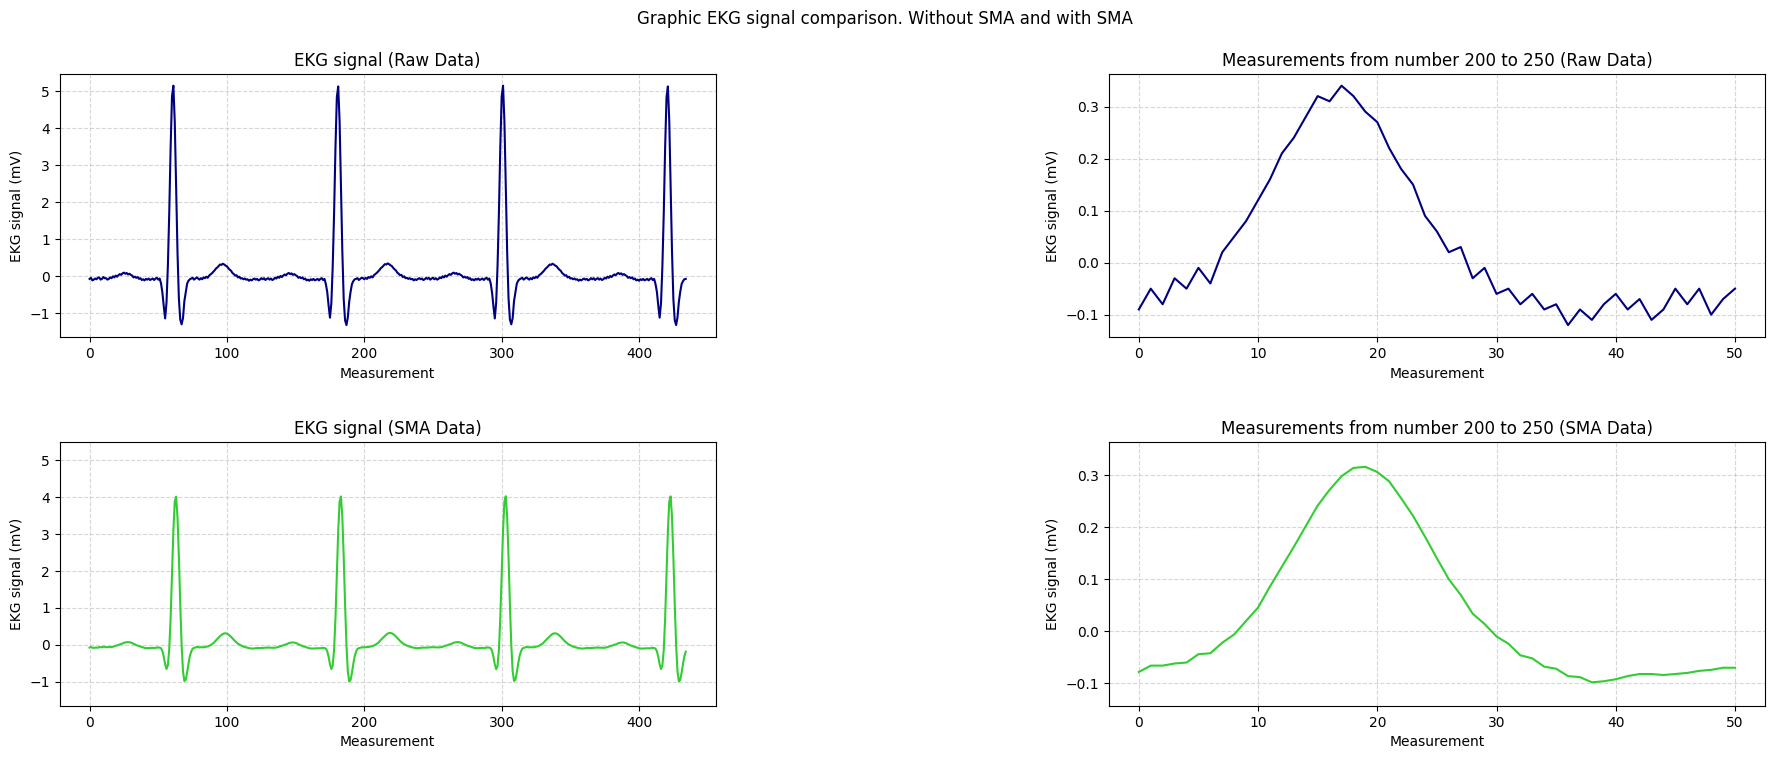

In [ ]:

raw_data = pd.read_csv( "Holter_Raw_Data.csv", header = None )
sma_data = pd.read_csv( "Holter_SMA_Data.csv", header = None )

num_of_rec_raw = np.arange(0,len(raw_data),1)
EKG_signal_raw = raw_data.values

num_of_rec_sma = np.arange(0,len(sma_data),1)
EKG_signal_sma = sma_data.values


fig, axes = plt.subplots(2,2, figsize = (22,8))
fig.suptitle("Graphic EKG signal comparison. Without SMA and with SMA")
fig.subplots_adjust( top = 0.9, hspace = 0.4, wspace = 0.6)

for i in range(2):
    for j in range(2):
        axes[i][j].set_facecolor( "white" )
        axes[i][j].set_xlabel( "Measurement" )
        axes[i][j].set_ylabel( "EKG signal (mV)" )
        axes[i][j].grid(True, linestyle = '--', alpha = 0.5)
        

axes[0][1].set_title( "Measurements from number 200 to 250 (Raw Data)" )
axes[1][1].set_title( "Measurements from number 200 to 250 (SMA Data)" )


axes[0][0].plot( num_of_rec_raw, EKG_signal_raw, color = "navy")
axes[0][0].set_title( "EKG signal (Raw Data)" )
axes[0][0].set_ylim(min(EKG_signal_raw), max(EKG_signal_raw))

axes[1][0].plot( num_of_rec_sma, EKG_signal_sma, color = "limegreen")
axes[1][0].set_title( "EKG signal (SMA Data)" )
axes[1][0].set_ylim( min(EKG_signal_sma), max(EKG_signal_sma) )

# exploiting only 50 records of data
sample_data_raw = raw_data.iloc[200:251].reset_index(drop = True)
sample_val_raw = sample_data_raw.values
sample_num_rec = np.arange(0, 51, 1)

sample_data_sma = sma_data.iloc[200:251].reset_index(drop = True)
sample_val_sma = sample_data_sma.values


axes[0][1].plot( sample_num_rec, sample_val_raw, color = "navy" )
axes[1][1].plot( sample_num_rec, sample_val_sma, color = "limegreen" )


global_min_sample = min( sample_val_raw.min(), sample_val_sma.min() )
global_max_sample = max( sample_val_raw.max(), sample_val_sma.max() )

margin = (global_max_sample - global_min_sample) * 0.05
lower_lim = global_min_sample - margin
upper_lim = global_max_sample + margin

axes[0][1].set_ylim( lower_lim, upper_lim )
axes[1][1].set_ylim( lower_lim, upper_lim )

global_min_all = min( EKG_signal_raw.min(), EKG_signal_sma.min() )
global_max_all = max( EKG_signal_raw.max(), EKG_signal_sma.max() )

margin_all = ( global_max_all - global_min_all ) * 0.05
axes[0][0].set_ylim( global_min_all - margin_all, global_max_all + margin_all )
axes[1][0].set_ylim( global_min_all - margin_all, global_max_all + margin_all )

plt.show()



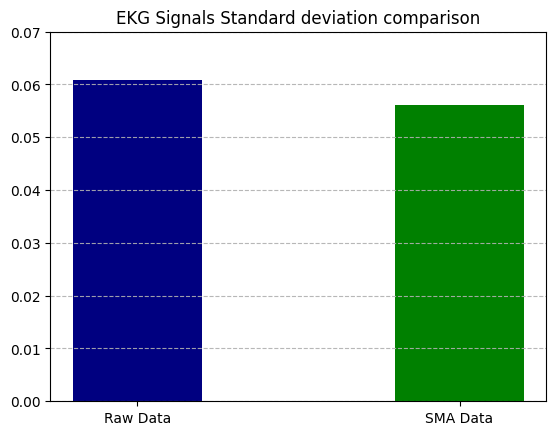

[np.float64(0.06092382404844859), np.float64(0.056108430987807136)]


In [252]:
# -------------STATISTICS---------------
#pomiary od 120 do 150  240 do 360  360 do 390

# calculating the standard deviation during intervals when the heart is resting

finterval_r = raw_data.iloc[120:151].reset_index( drop = True )
sinterval_r = raw_data.iloc[240:271].reset_index( drop = True )
tinterval_r = raw_data.iloc[360:391].reset_index( drop = True )
interval_r = pd.concat([finterval_r, sinterval_r, tinterval_r]).to_numpy()
std_r = np.std(interval_r)

finterval_s = sma_data.iloc[120:151].reset_index( drop = True )
sinterval_s = sma_data.iloc[240:271].reset_index( drop = True )
tinterval_s = sma_data.iloc[360:391].reset_index( drop = True )
interval_s = pd.concat([finterval_s, sinterval_s, tinterval_s]).to_numpy()
std_s = np.std(interval_s)


groups = ['Raw Data', 'SMA Data']
values = [std_r, std_s]

plt.bar( groups, values, color=['navy', 'green'], width = 0.4 )

plt.title( 'EKG Signals Standard deviation comparison' )
plt.grid( axis='y', linestyle='--', alpha=0.9, zorder=0 )
plt.yticks(np.arange(0, 0.07, 0.01))
plt.ylim(0, 0.07)
plt.show()

print(values)


In [211]:

diff_raw = interval_r.max() - interval_r.min()

diff_sma = interval_s.max() - interval_s.min()


print( f"Maximum noise in amplitude when the heart is at rest. Raw Data : {diff_raw:.2f}    SMA Data : {diff_sma:.2f}" )


Maximum noise in amplitude when the heart is at rest. Raw Data : 0.21    SMA Data : 0.17


In [212]:
# Calculating trend changes

# raw data : 

changes_r = 0
prev_trend_r = None
index_r = []

for i in range(1, len(sample_val_raw) ):
    current_r = sample_val_raw[i]
    prev_r = sample_val_raw[i - 1]
    
    if current_r - prev_r > 0:
        curr_trend_r = "up"
    elif current_r - prev_r < 0:
        curr_trend_r = "down"
    
    if prev_trend_r != None and curr_trend_r != prev_trend_r:
        changes_r = changes_r + 1 
        index_r.append((i)) 
    
    prev_trend_r = curr_trend_r

# SMA data : 
changes_s = 0 
prev_trend_s = None 
index_s = []

for j in range(1, len(sample_val_sma)):
    current_s = sample_val_sma[j]
    prev_s = sample_val_sma[j-1]

    if current_s - prev_s > 0:
        curr_trend_s = "up"
    elif current_s - prev_s < 0:
        curr_trend_s = "down"
    
    if prev_trend_s != None and curr_trend_s != prev_trend_s:
        changes_s = changes_s + 1 
        index_s.append((j))
    
    prev_trend_s = curr_trend_s

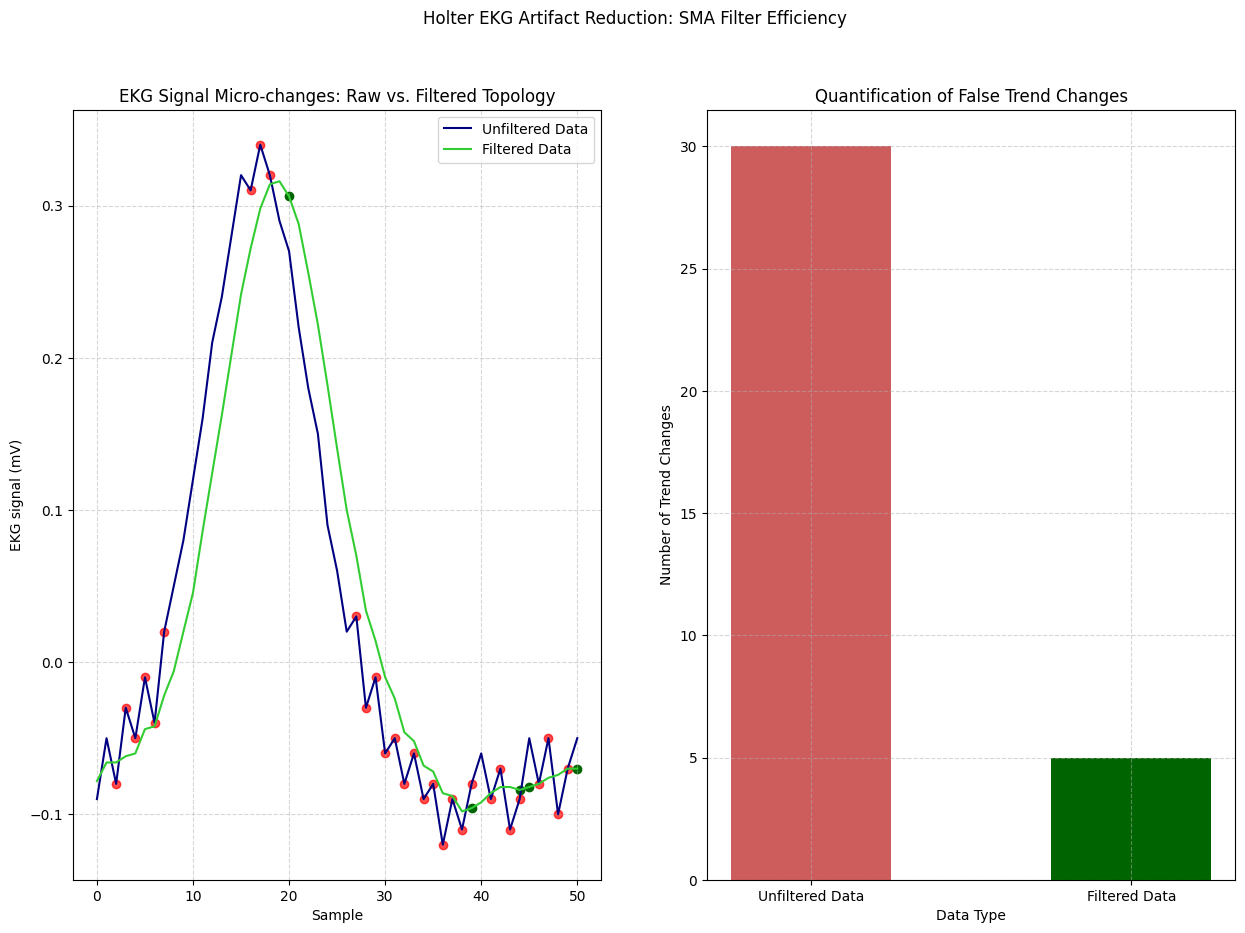

In [246]:
# Visualization of trends

fig, axes = plt.subplots(1,2, figsize=(15,10))
fig.suptitle( "Holter EKG Artifact Reduction: SMA Filter Efficiency" )


axes[0].plot( sample_num_rec, sample_val_raw, color = "navy" )
axes[0].plot( sample_num_rec, sample_val_sma, color = "limegreen" )
axes[0].legend(['Unfiltered Data','Filtered Data'])
axes[0].grid(True, linestyle = '--', alpha = 0.5)
axes[0].set_ylim(min(sample_val_raw) - margin, max(sample_val_raw) + margin) 

axes[0].set_title( "EKG Signal Micro-changes: Raw vs. Filtered Topology" )
axes[0].scatter( index_r, sample_val_raw[index_r], marker = 'o', alpha = 0.7, color = "red" )
axes[0].scatter( index_s, sample_val_sma[index_s], marker = 'o', alpha = 1, color = "darkgreen" )
axes[0].set_xlabel("Sample")
axes[0].set_ylabel("EKG signal (mV)")

axes[1].set_title( "Quantification of False Trend Changes" )
axes[1].bar(['Unfiltered Data', 'Filtered Data'], [changes_r, changes_s], width = 0.5, color = ['indianred', 'darkgreen'])
axes[1].grid(True, linestyle = '--', alpha = 0.5)
axes[1].set_xlabel("Data Type")
axes[1].set_ylabel("Number of Trend Changes")


plt.show()